# Tugas 05: Transfer Learning untuk Klasifikasi Citra dengan Data Terbatas

**Nama:** Rizky Mirzaviandy Priambodo  
**NIM:** 2802549041

In [1]:
import copy
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.datasets import OxfordIIITPet

SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 20
PATIENCE = 4
NUM_CLASSES = 10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

## 1. Data: 10 kelas, split stratified 70/15/15

In [2]:
CLASSES = [
    "Bengal", "Birman", "British Shorthair", "Ragdoll", "Russian Blue",
    "American Pit Bull Terrier", "Basset Hound", "Beagle", "Pug", "Staffordshire Bull Terrier",
]


def collect_subset():
    paths, labels = [], []
    for split in ("trainval", "test"):
        dataset = OxfordIIITPet("data", split=split, download=True)
        for path, label in zip(dataset._images, dataset._labels):
            breed = dataset.classes[label]
            if breed in CLASSES:
                paths.append(str(path))
                labels.append(CLASSES.index(breed))
    return paths, labels


paths, labels = collect_subset()
train_paths, rest_paths, train_labels, rest_labels = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    rest_paths, rest_labels, test_size=0.50, stratify=rest_labels, random_state=SEED)
test_labels = np.array(test_labels)
print(f"train={len(train_paths)} val={len(val_paths)} test={len(test_paths)}")

train=1392 val=298 test=299


In [3]:
RESNET_WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1
MEAN = RESNET_WEIGHTS.transforms().mean
STD = RESNET_WEIGHTS.transforms().std

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


def load_images(image_paths):
    resize = transforms.Resize(256)
    return [resize(Image.open(path).convert("RGB")) for path in image_paths]


class PetDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        return self.transform(self.images[index]), int(self.labels[index])


def make_loader(images, labels, transform, shuffle=False):
    return DataLoader(
        PetDataset(images, labels, transform),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=torch.Generator().manual_seed(SEED),
    )


train_images = load_images(train_paths)
val_images = load_images(val_paths)
test_images = load_images(test_paths)

val_loader = make_loader(val_images, val_labels, eval_transform)
test_loader = make_loader(test_images, test_labels, eval_transform)
train_eval_loader = make_loader(train_images, train_labels, eval_transform)

## 2. Model, evaluasi, dan training dengan early stopping

In [4]:
def build_resnet(condition):
    if condition == "B1":
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(512, NUM_CLASSES)
        return model, [("all", model.parameters(), 1e-3)]

    model = models.resnet18(weights=RESNET_WEIGHTS)
    model.requires_grad_(False)
    model.fc = nn.Linear(512, NUM_CLASSES)
    if condition == "B2":
        return model, [("fc", model.fc.parameters(), 1e-3)]

    model.layer4.requires_grad_(True)
    return model, [("layer4", model.layer4.parameters(), 1e-4), ("fc", model.fc.parameters(), 1e-3)]


def build_efficientnet():
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    model.requires_grad_(False)
    model.classifier[1] = nn.Linear(1280, NUM_CLASSES)
    last_blocks = model.features[6:]
    last_blocks.requires_grad_(True)
    return model, [("features[6:]", last_blocks.parameters(), 1e-4), ("classifier", model.classifier.parameters(), 1e-3)]


def build_model(condition):
    model, param_groups = build_efficientnet() if condition == "B5" else build_resnet(condition)
    return model.to(DEVICE), param_groups


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, labels, probs = 0.0, [], []
    for images, targets in loader:
        logits = model(images.to(DEVICE)).cpu()
        total_loss += F.cross_entropy(logits, targets, reduction="sum").item()
        labels.append(targets)
        probs.append(logits.softmax(1))
    labels = torch.cat(labels).numpy()
    probs = torch.cat(probs).numpy()
    preds = probs.argmax(1)
    return {
        "loss": total_loss / len(labels),
        "acc": (preds == labels).mean(),
        "f1": f1_score(labels, preds, average="macro"),
        "labels": labels,
        "preds": preds,
        "probs": probs,
    }


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    for images, targets in loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad()
        loss = F.cross_entropy(model(images), targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(targets)
    return total_loss / len(loader.dataset)


HISTORY, SUMMARY, MODELS = [], [], {}


def run_experiment(name, condition, augment):
    set_seed()
    model, param_groups = build_model(condition)
    optimizer = torch.optim.AdamW([{"params": params, "lr": lr} for _, params, lr in param_groups], weight_decay=1e-2)
    train_loader = make_loader(train_images, train_labels, train_transform if augment else eval_transform, shuffle=True)

    best_loss, epochs_without_improvement = float("inf"), 0
    start = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer)
        train_result = evaluate(model, train_eval_loader)
        val_result = evaluate(model, val_loader)
        HISTORY.append({"run": name, "epoch": epoch, "train_loss": train_loss, "train_acc": train_result["acc"],
                        "val_loss": val_result["loss"], "val_acc": val_result["acc"]})

        if val_result["loss"] < best_loss:
            best_loss, best_epoch, epochs_without_improvement = val_result["loss"], epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement == PATIENCE:
                break
    train_time = time.time() - start

    model.load_state_dict(best_state)
    train_result = evaluate(model, train_eval_loader)
    val_result = evaluate(model, val_loader)
    test_result = evaluate(model, test_loader)
    SUMMARY.append({
        "run": name,
        "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "lr": {group: lr for group, _, lr in param_groups},
        "best_epoch": best_epoch,
        "epochs_run": epoch,
        "train_time_s": round(train_time, 1),
        "train_acc": train_result["acc"],
        "val_acc": val_result["acc"],
        "test_acc": test_result["acc"],
        "test_macro_f1": test_result["f1"],
        "gap_train_val": train_result["acc"] - val_result["acc"],
    })
    MODELS[name] = model
    print(SUMMARY[-1])

## 3. Eksperimen B1 sampai B5

In [5]:
run_experiment("B1_scratch", "B1", augment=True)

{'run': 'B1_scratch', 'trainable_params': 11181642, 'lr': {'all': 0.001}, 'best_epoch': 10, 'epochs_run': 14, 'train_time_s': 109.3, 'train_acc': np.float64(0.47772988505747127), 'val_acc': np.float64(0.4261744966442953), 'test_acc': np.float64(0.44481605351170567), 'test_macro_f1': 0.4100665509795046, 'gap_train_val': np.float64(0.05155538841317597)}


In [6]:
run_experiment("B2_feature_extraction", "B2", augment=True)

{'run': 'B2_feature_extraction', 'trainable_params': 5130, 'lr': {'fc': 0.001}, 'best_epoch': 12, 'epochs_run': 16, 'train_time_s': 78.7, 'train_acc': np.float64(0.9310344827586207), 'val_acc': np.float64(0.8523489932885906), 'test_acc': np.float64(0.8494983277591973), 'test_macro_f1': 0.8507638506299189, 'gap_train_val': np.float64(0.07868548947003007)}


In [7]:
run_experiment("B3_finetune_aug", "B3", augment=True)

{'run': 'B3_finetune_aug', 'trainable_params': 8398858, 'lr': {'layer4': 0.0001, 'fc': 0.001}, 'best_epoch': 2, 'epochs_run': 6, 'train_time_s': 31.7, 'train_acc': np.float64(0.9454022988505747), 'val_acc': np.float64(0.8590604026845637), 'test_acc': np.float64(0.862876254180602), 'test_macro_f1': 0.8618114329975812, 'gap_train_val': np.float64(0.08634189616601096)}


B4 adalah kondisi B3 tanpa augmentasi. Versi dengan augmentasi adalah run B3 di atas.

In [8]:
run_experiment("B4_finetune_noaug", "B3", augment=False)

{'run': 'B4_finetune_noaug', 'trainable_params': 8398858, 'lr': {'layer4': 0.0001, 'fc': 0.001}, 'best_epoch': 2, 'epochs_run': 6, 'train_time_s': 22.1, 'train_acc': np.float64(0.9942528735632183), 'val_acc': np.float64(0.8557046979865772), 'test_acc': np.float64(0.8729096989966555), 'test_macro_f1': 0.8725850254916413, 'gap_train_val': np.float64(0.13854817557664112)}


In [9]:
run_experiment("B5_efficientnet_b0", "B5", augment=True)

{'run': 'B5_efficientnet_b0', 'trainable_params': 3168550, 'lr': {'features[6:]': 0.0001, 'classifier': 0.001}, 'best_epoch': 7, 'epochs_run': 11, 'train_time_s': 72.8, 'train_acc': np.float64(0.9942528735632183), 'val_acc': np.float64(0.8993288590604027), 'test_acc': np.float64(0.9364548494983278), 'test_macro_f1': 0.9365221333411325, 'gap_train_val': np.float64(0.09492401450281562)}


## 4. Tabel konsolidasi dan kurva loss

,run,trainable_params,lr,best_epoch,epochs_run,train_time_s,train_acc,val_acc,test_acc,test_macro_f1,gap_train_val
0,B1_scratch,11181642,{'all': 0.001},10,14,109.3,0.4777,0.4262,0.4448,0.4101,0.0516
1,B2_feature_extraction,5130,{'fc': 0.001},12,16,78.7,0.9310,0.8523,0.8495,0.8508,0.0787
2,B3_finetune_aug,8398858,"{'layer4': 0.0001, 'fc': 0.001}",2,6,31.7,0.9454,0.8591,0.8629,0.8618,0.0863
3,B4_finetune_noaug,8398858,"{'layer4': 0.0001, 'fc': 0.001}",2,6,22.1,0.9943,0.8557,0.8729,0.8726,0.1385
4,B5_efficientnet_b0,3168550,"{'features[6:]': 0.0001, 'classifier': 0.001}",7,11,72.8,0.9943,0.8993,0.9365,0.9365,0.0949


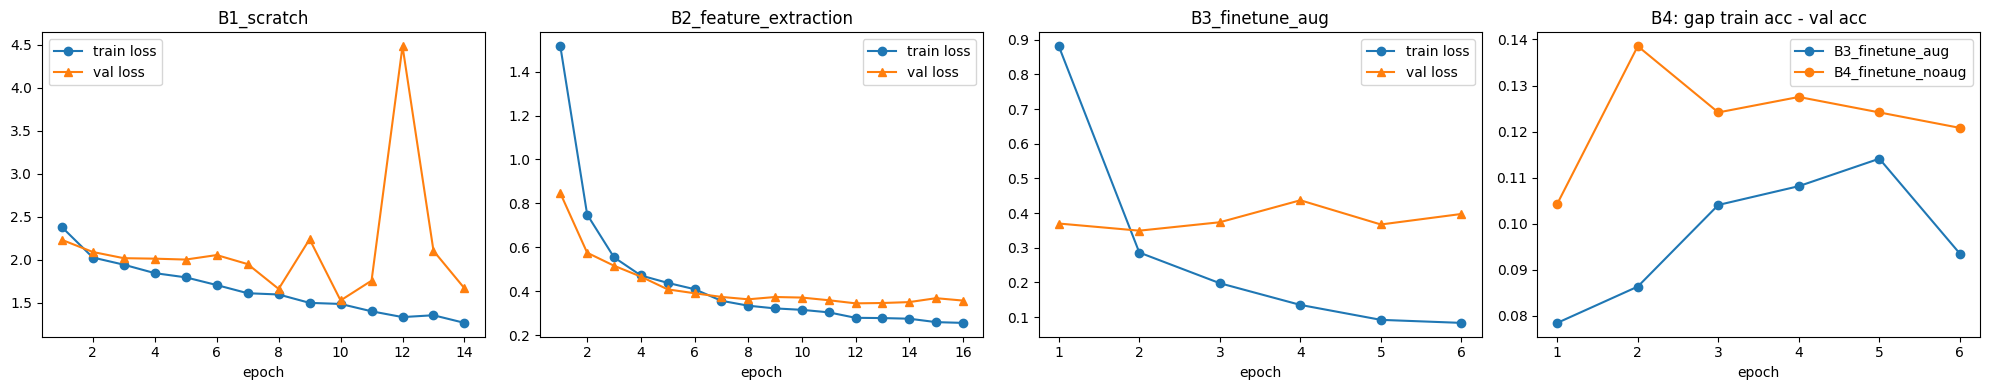

In [10]:
display(pd.DataFrame(SUMMARY).round(4))
history = pd.DataFrame(HISTORY)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, run in zip(axes, ["B1_scratch", "B2_feature_extraction", "B3_finetune_aug"]):
    run_history = history[history.run == run]
    ax.plot(run_history.epoch, run_history.train_loss, "o-", label="train loss")
    ax.plot(run_history.epoch, run_history.val_loss, "^-", label="val loss")
    ax.set_title(run)
    ax.set_xlabel("epoch")
    ax.legend()

for run in ["B3_finetune_aug", "B4_finetune_noaug"]:
    run_history = history[history.run == run]
    axes[3].plot(run_history.epoch, run_history.train_acc - run_history.val_acc, "o-", label=run)
axes[3].set_title("B4: gap train acc - val acc")
axes[3].set_xlabel("epoch")
axes[3].legend()
plt.tight_layout()
plt.show()

## 5. Failure analysis pada model ResNet-18 terbaik

B3_finetune_aug | salah: 41 / 299


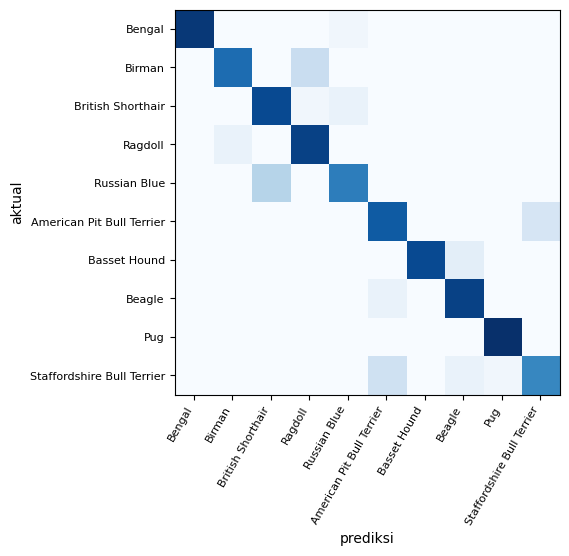

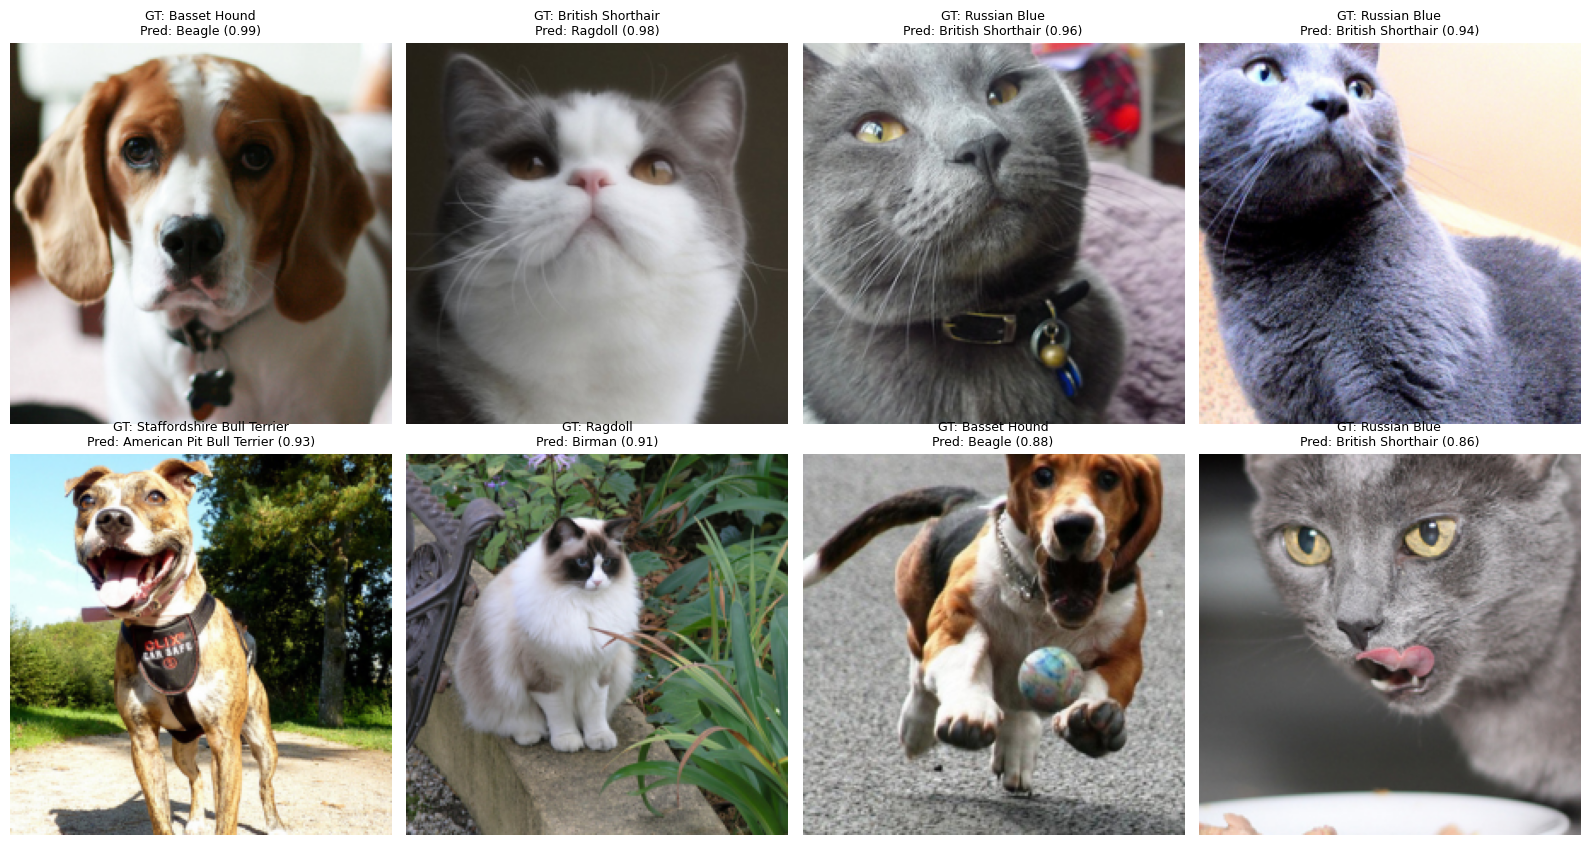

In [11]:
resnet_runs = [s for s in SUMMARY if s["run"] != "B5_efficientnet_b0"]
best_run = max(resnet_runs, key=lambda s: s["val_acc"])["run"]
result = evaluate(MODELS[best_run], test_loader)
wrong = np.where(result["labels"] != result["preds"])[0]
print(f"{best_run} | salah: {len(wrong)} / {len(result['labels'])}")

plt.figure(figsize=(6, 5))
plt.imshow(confusion_matrix(result["labels"], result["preds"]), cmap="Blues")
plt.xticks(range(NUM_CLASSES), CLASSES, rotation=60, ha="right", fontsize=8)
plt.yticks(range(NUM_CLASSES), CLASSES, fontsize=8)
plt.xlabel("prediksi")
plt.ylabel("aktual")
plt.show()

most_confident_wrong = wrong[np.argsort(-result["probs"][wrong].max(1))][:8]
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for ax, index in zip(axes.flat, most_confident_wrong):
    actual = CLASSES[result["labels"][index]]
    predicted = CLASSES[result["preds"][index]]
    confidence = result["probs"][index].max()
    ax.imshow(transforms.CenterCrop(224)(test_images[index]))
    ax.set_title(f"GT: {actual}\nPred: {predicted} ({confidence:.2f})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Grad-CAM layer4 sebelum (B2, layer4 ImageNet beku) dan sesudah fine tuning (B3)

<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


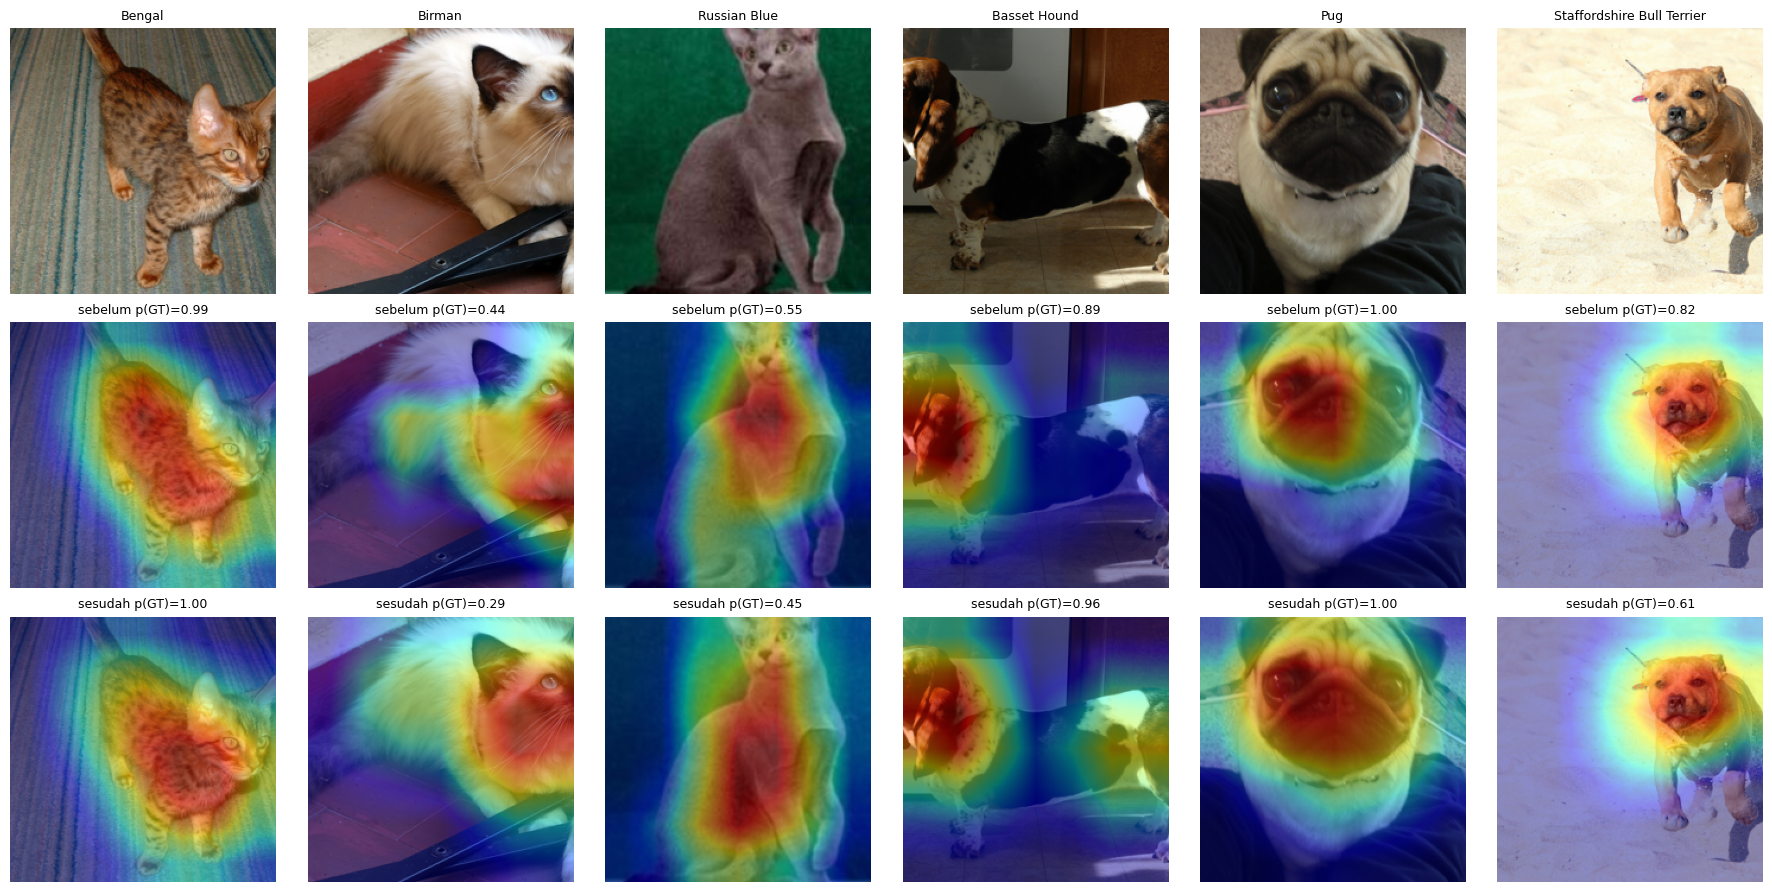

cosine similarity fitur layer4 sebelum vs sesudah: 0.8756


In [12]:
def grad_cam(model, image, target_class):
    captured = {}
    forward_hook = model.layer4.register_forward_hook(lambda module, inp, out: captured.update(activation=out))
    backward_hook = model.layer4.register_full_backward_hook(lambda module, grad_in, grad_out: captured.update(gradient=grad_out[0]))
    model.eval()
    model.zero_grad()
    model(image)[0, target_class].backward()
    forward_hook.remove()
    backward_hook.remove()

    channel_weights = captured["gradient"].mean((2, 3), keepdim=True)
    cam = F.relu((channel_weights * captured["activation"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=224, mode="bilinear")[0, 0].detach().cpu()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)


def class_probability(model, image, target_class):
    return model(image).softmax(1)[0, target_class].item()


model_before = MODELS["B2_feature_extraction"]
model_after = MODELS["B3_finetune_aug"]
model_before.requires_grad_(True)

rng = np.random.RandomState(SEED)
sample_indices = [rng.choice(np.where(test_labels == c)[0]) for c in (0, 1, 4, 6, 8, 9)]

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for col, index in enumerate(sample_indices):
    image = eval_transform(test_images[index]).unsqueeze(0).to(DEVICE)
    picture = transforms.CenterCrop(224)(test_images[index])
    target = test_labels[index]
    axes[0, col].imshow(picture)
    axes[0, col].set_title(CLASSES[target], fontsize=9)
    for row, (label, model) in ((1, ("sebelum", model_before)), (2, ("sesudah", model_after))):
        axes[row, col].imshow(picture)
        axes[row, col].imshow(grad_cam(model, image, target), cmap="jet", alpha=0.45)
        axes[row, col].set_title(f"{label} p(GT)={class_probability(model, image, target):.2f}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()


def pooled_features(model, images):
    backbone = nn.Sequential(*list(model.children())[:-1])
    return backbone(images).flatten(1)


similarities = []
with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE)
        similarities.append(F.cosine_similarity(pooled_features(model_before, images), pooled_features(model_after, images)).cpu())
print(f"cosine similarity fitur layer4 sebelum vs sesudah: {torch.cat(similarities).mean().item():.4f}")

## 7. Simpan log

In [13]:
pd.DataFrame(HISTORY).to_csv("history.csv", index=False)
config = {
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "optimizer": "AdamW(weight_decay=1e-2)",
    "device": str(DEVICE),
    "split": {"train": len(train_paths), "val": len(val_paths), "test": len(test_paths)},
}
with open("summary.json", "w") as f:
    json.dump({**config, "runs": SUMMARY}, f, indent=2)
print(pd.read_csv("history.csv").shape)

(53, 6)
